# Leukemia Subtype Detection with Ensemble Learning & Grad-CAM
Using dataset manually uploaded to Google Drive and extracted in Colab.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Leukemia Dataset/archive (2).zip'
extract_path = '/content/leukemia_dataset'

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

In [ ]:
dataset_dir = os.path.join(extract_path, "Original")
print("Dataset extracted to:", dataset_dir)


Dataset extracted to: /content/leukemia_dataset/Original


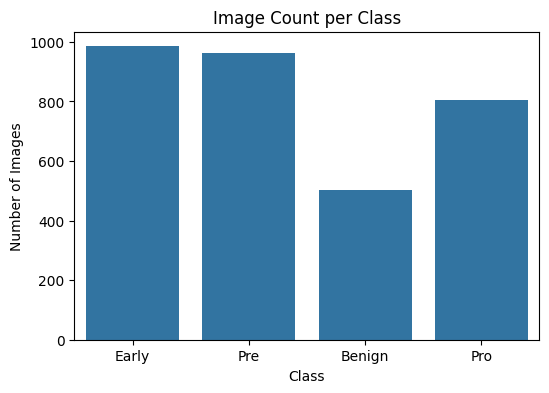

Image Resolution Statistics:
       Width  Height
count   20.0    20.0
mean   224.0   224.0
std      0.0     0.0
min    224.0   224.0
25%    224.0   224.0
50%    224.0   224.0
75%    224.0   224.0
max    224.0   224.0


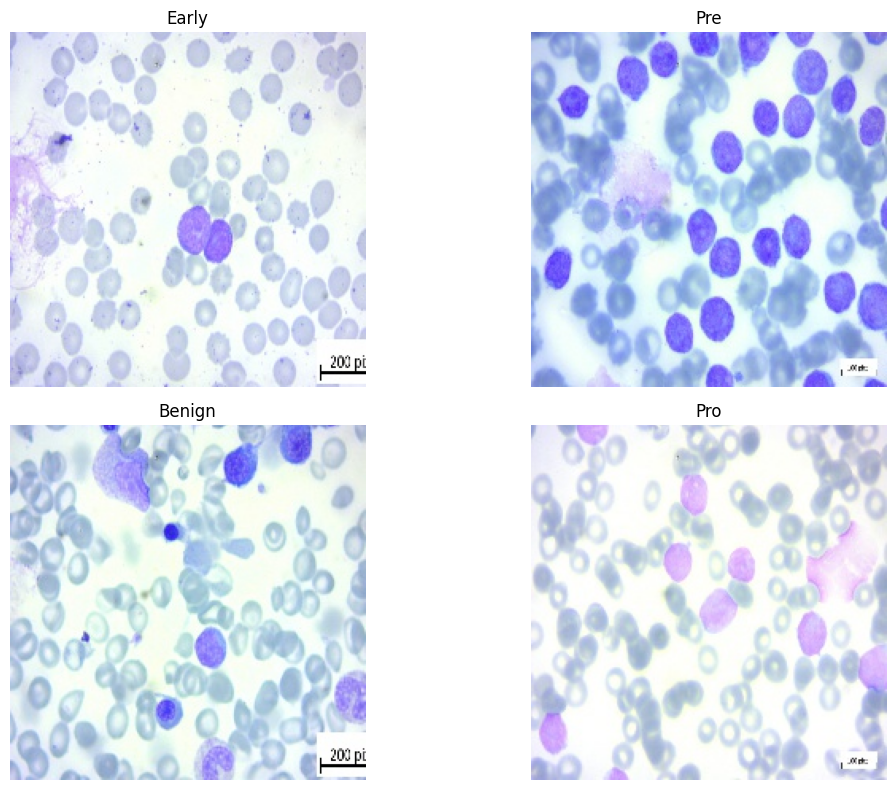

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import pandas as pd

# Path to dataset
dataset_dir = os.path.join(extract_path, "Original")

# 1. Count images per class
class_counts = {}
image_shapes = []

for label in os.listdir(dataset_dir):
    label_path = os.path.join(dataset_dir, label)
    if os.path.isdir(label_path):
        files = [f for f in os.listdir(label_path) if f.endswith(('.jpg', '.png'))]
        class_counts[label] = len(files)

        # Gather resolution info
        for f in files[:5]:  # just sample first 5 per class
            img = Image.open(os.path.join(label_path, f))
            image_shapes.append(img.size)

# 2. Plot class distribution
plt.figure(figsize=(6,4))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title("Image Count per Class")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.show()

# 3. Print resolution stats
df_shapes = pd.DataFrame(image_shapes, columns=['Width', 'Height'])
print("Image Resolution Statistics:")
print(df_shapes.describe())

# 4. Visualize samples from each class
import random

plt.figure(figsize=(12, 8))
for i, label in enumerate(class_counts.keys()):
    sample_dir = os.path.join(dataset_dir, label)
    sample_image = random.choice(os.listdir(sample_dir))
    img_path = os.path.join(sample_dir, sample_image)
    img = Image.open(img_path)

    plt.subplot(2, 2, i+1)
    plt.imshow(img)
    plt.title(label)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import os
import numpy as np
import pickle
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D
from tensorflow.keras.applications import DenseNet121, EfficientNetV2B0, ResNet50, InceptionV3
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations


In [ ]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
NUM_CLASSES = 4
EPOCHS = 20
LEARNING_RATE = 1e-4
SAVE_DIR = "saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)
class_names = ['Benign', 'Pre', 'Pro', 'Early']


In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_dir, target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE, class_mode='categorical',
    subset='training', shuffle=True)

val_generator = datagen.flow_from_directory(
    dataset_dir, target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE, class_mode='categorical',
    subset='validation', shuffle=False)


Found 2607 images belonging to 4 classes.
Found 649 images belonging to 4 classes.


In [ ]:
def build_model(base_model_fn, name):
    base = base_model_fn(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    base.trainable = False
    x = GlobalAveragePooling2D()(base.output)
    out = Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=out, name=name)
    model.compile(optimizer=Adam(LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    return model


In [ ]:
# --- Imports ---
import numpy as np
import os, pickle
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight

# --- Image Parameters ---
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32
NUM_CLASSES = 4
INITIAL_EPOCHS = 20
FINE_TUNE_EPOCHS = 10
LEARNING_RATE = 1e-4

# --- Save Directory ---
SAVE_DIR = os.path.join("savedmodels2", "DenseNet121")
os.makedirs(SAVE_DIR, exist_ok=True)

# --- Dataset Path (already unzipped) ---
dataset_dir = "/content/leukemia_dataset/Original"

# --- Data Augmentation ---
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# --- Compute Class Weights ---
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights))

# --- Build DenseNet121 with Dropout & L2 ---
def build_model():
    base = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    base.trainable = False  # freeze base initially

    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inputs=base.input, outputs=output, name="DenseNet121")
    return model

model = build_model()

model.compile(optimizer=Adam(LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])

# --- Callbacks ---
callbacks = [
    EarlyStopping(patience=5, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=3, factor=0.3, min_lr=1e-6)
]

# --- Phase 1: Train with base frozen ---
print("\n Phase 1: Training DenseNet121 (frozen base)...\n")
history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Phase 2: Fine-tune top layers ---
print("\nPhase 2: Fine-tuning top layers...\n")
model.trainable = True
for layer in model.layers[:len(model.layers)//2]:  # Freeze bottom half
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Save weights & history ---
model.save_weights(os.path.join(SAVE_DIR, "DenseNet121.weights.h5"))

# Merge both histories and save
merged_history = history1.history
for key in history2.history:
    merged_history[key] = merged_history.get(key, []) + history2.history[key]

with open(os.path.join(SAVE_DIR, "DenseNet121_history.pkl"), 'wb') as f:
    pickle.dump(merged_history, f)

print("\nDenseNet121 fully trained and saved to:", SAVE_DIR)


Found 2607 images belonging to 4 classes.
Found 649 images belonging to 4 classes.

 Phase 1: Training DenseNet121 (frozen base)...



/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.3301 - loss: 1.6079 - val_accuracy: 0.6471 - val_loss: 1.2051 - learning_rate: 1.0000e-04
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 42s 511ms/step - accuracy: 0.6848 - loss: 1.1383 - val_accuracy: 0.7612 - val_loss: 0.9617 - learning_rate: 1.0000e-04
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 79s 472ms/step - accuracy: 0.8017 - loss: 0.8615 - val_accuracy: 0.7735 - val_loss: 0.8715 - learning_rate: 1.0000e-04
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 42s 515ms/step - accuracy: 0.8405 - loss: 0.7105 - val_accuracy: 0.7874 - val_loss: 0.8457 - learning_rate: 1.0000e-04
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 39s 480ms/step - accuracy: 0.8823 - loss: 0.5985 - val_accuracy: 0.8028 - val_loss: 0.7677 - learning_rate: 1.0000e-04
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 41s 500ms/step - accuracy: 0.8809 - loss: 0.5413 - val_accuracy: 0.7935 - val_loss: 0.7728 - learning_rate: 1.0000e-04
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 39s 479ms/step - accur

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

# Predict on validation set
val_preds = model.predict(val_generator)
y_pred = np.argmax(val_preds, axis=1)
y_true = val_generator.classes[val_generator.index_array]

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f" DenseNet121 Validation Accuracy: {acc:.4f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step
 DenseNet121 Validation Accuracy: 0.8952


In [ ]:
# --- Imports ---
import numpy as np
import os, pickle
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight

# --- Image Parameters ---
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32
NUM_CLASSES = 4
INITIAL_EPOCHS = 20
FINE_TUNE_EPOCHS = 10
LEARNING_RATE = 1e-4

# --- Save Directory ---
SAVE_DIR = os.path.join("savedmodels2", "InceptionV3")
os.makedirs(SAVE_DIR, exist_ok=True)

# --- Dataset Path (already unzipped) ---
dataset_dir = "/content/leukemia_dataset/Original"

# --- Data Augmentation ---
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# --- Class Weights ---
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights))

# --- Build InceptionV3 Model ---
def build_model():
    base = InceptionV3(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    base.trainable = False

    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inputs=base.input, outputs=output, name="InceptionV3")
    return model

model = build_model()
model.compile(optimizer=Adam(LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])

# --- Callbacks ---
callbacks = [
    EarlyStopping(patience=5, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=3, factor=0.3, min_lr=1e-6)
]

# --- Phase 1: Train with base frozen ---
print("\n Phase 1: Training InceptionV3 (frozen base)...\n")
history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Phase 2: Fine-tuning ---
print("\n Phase 2: Fine-tuning top layers...\n")
model.trainable = True
for layer in model.layers[:len(model.layers)//2]:
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Save Weights & History ---
model.save_weights(os.path.join(SAVE_DIR, "InceptionV3.weights.h5"))

# Merge histories
merged_history = history1.history
for key in history2.history:
    merged_history[key] = merged_history.get(key, []) + history2.history[key]

with open(os.path.join(SAVE_DIR, "InceptionV3_history.pkl"), 'wb') as f:
    pickle.dump(merged_history, f)

print("\n InceptionV3 training complete and saved to:", SAVE_DIR)


Found 2607 images belonging to 4 classes.
Found 649 images belonging to 4 classes.
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 Phase 1: Training InceptionV3 (frozen base)...



/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 80s 751ms/step - accuracy: 0.3992 - loss: 1.5238 - val_accuracy: 0.6795 - val_loss: 1.0564 - learning_rate: 1.0000e-04
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 41s 496ms/step - accuracy: 0.7192 - loss: 1.0015 - val_accuracy: 0.7504 - val_loss: 0.9083 - learning_rate: 1.0000e-04
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 490ms/step - accuracy: 0.8179 - loss: 0.7958 - val_accuracy: 0.7720 - val_loss: 0.8873 - learning_rate: 1.0000e-04
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 41s 495ms/step - accuracy: 0.8345 - loss: 0.7048 - val_accuracy: 0.7689 - val_loss: 0.8337 - learning_rate: 1.0000e-04
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 492ms/step - accuracy: 0.8514 - loss: 0.6538 - val_accuracy: 0.8151 - val_loss: 0.7383 - learning_rate: 1.0000e-04
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 484ms/step - accuracy: 0.8455 - loss: 0.6777 - val_accuracy: 0.8012 - val_loss: 0.7344 - learning_rate: 1.0000e-04
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 492ms/step - acc

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

# Predict on validation set
val_preds = model.predict(val_generator)
y_pred = np.argmax(val_preds, axis=1)
y_true = val_generator.classes[val_generator.index_array]

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f"InceptionV3 Validation Accuracy: {acc:.4f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 678ms/step
InceptionV3 Validation Accuracy: 0.8798


In [ ]:
# --- Imports ---
import numpy as np
import os, pickle
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight

# --- Image Parameters ---
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32
NUM_CLASSES = 4
INITIAL_EPOCHS = 20
FINE_TUNE_EPOCHS = 10
LEARNING_RATE = 1e-4

# --- Save Directory ---
SAVE_DIR = os.path.join("savedmodels2", "MobileNetV2")
os.makedirs(SAVE_DIR, exist_ok=True)

# --- Dataset Path (already unzipped) ---
dataset_dir = "/content/leukemia_dataset/Original"

# --- Data Augmentation ---
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# --- Class Weights ---
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights))

# --- Build MobileNetV2 Model ---
def build_model():
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    base.trainable = False

    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inputs=base.input, outputs=output, name="MobileNetV2")
    return model

model = build_model()
model.compile(optimizer=Adam(LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])

# --- Callbacks ---
callbacks = [
    EarlyStopping(patience=5, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=3, factor=0.3, min_lr=1e-6)
]

# --- Phase 1: Train with base frozen ---
print("\n Phase 1: Training MobileNetV2 (frozen base)...\n")
history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Phase 2: Fine-tuning ---
print("\n Phase 2: Fine-tuning top layers...\n")
model.trainable = True
for layer in model.layers[:len(model.layers)//2]:
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

# --- Save Weights & History ---
model.save_weights(os.path.join(SAVE_DIR, "MobileNetV2.weights.h5"))

# Merge histories
merged_history = history1.history
for key in history2.history:
    merged_history[key] = merged_history.get(key, []) + history2.history[key]

with open(os.path.join(SAVE_DIR, "MobileNetV2_history.pkl"), 'wb') as f:
    pickle.dump(merged_history, f)

print("\n MobileNetV2 training complete and saved to:", SAVE_DIR)


Found 2607 images belonging to 4 classes.
Found 649 images belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 Phase 1: Training MobileNetV2 (frozen base)...



/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 61s 605ms/step - accuracy: 0.3802 - loss: 1.5688 - val_accuracy: 0.7427 - val_loss: 0.9805 - learning_rate: 1.0000e-04
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 39s 483ms/step - accuracy: 0.7663 - loss: 0.9326 - val_accuracy: 0.8290 - val_loss: 0.7628 - learning_rate: 1.0000e-04
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 36s 444ms/step - accuracy: 0.8285 - loss: 0.6961 - val_accuracy: 0.8536 - val_loss: 0.6594 - learning_rate: 1.0000e-04
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 42s 451ms/step - accuracy: 0.8888 - loss: 0.5706 - val_accuracy: 0.8690 - val_loss: 0.5891 - learning_rate: 1.0000e-04
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 36s 440ms/step - accuracy: 0.8859 - loss: 0.5367 - val_accuracy: 0.8783 - val_loss: 0.5190 - learning_rate: 1.0000e-04
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 38s 467ms/step - accuracy: 0.8972 - loss: 0.4864 - val_accuracy: 0.8844 - val_loss: 0.5245 - learning_rate: 1.0000e-04
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 37s 453ms/step - acc

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

# Predict on validation set
val_preds = model.predict(val_generator)
y_pred = np.argmax(val_preds, axis=1)
y_true = val_generator.classes[val_generator.index_array]

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f" MobileNetV2 Validation Accuracy: {acc:.4f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 14s 497ms/step
 MobileNetV2 Validation Accuracy: 0.9445


In [ ]:
# --- Common Imports ---
from tensorflow.keras.models import Model
from tensorflow.keras.applications import DenseNet121, InceptionV3, MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.regularizers import l2
import numpy as np
import os

IMG_SHAPE = (224, 224, 3)
NUM_CLASSES = 4
SAVE_DIR = "savedmodels2"

def build_model(base_model_fn, model_name):
    base = base_model_fn(include_top=False, weights='imagenet', input_shape=IMG_SHAPE)
    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=output, name=model_name)
    return model

# Build and load models
models = {}
for name, fn in {
    "DenseNet121": DenseNet121,
    "InceptionV3": InceptionV3,
    "MobileNetV2": MobileNetV2
}.items():
    model = build_model(fn, name)
    weight_path = os.path.join(SAVE_DIR, name, f"{name}.weights.h5")
    model.load_weights(weight_path)
    models[name] = model


In [ ]:
from itertools import combinations
from sklearn.metrics import accuracy_score

# Predictions from all models
predictions = {}
for name, model in models.items():
    preds = model.predict(val_generator)
    predictions[name] = preds

# Ground truth
true_labels = val_generator.classes[val_generator.index_array]

# Evaluate all combinations
print("\n Ensemble Combination Accuracies\n" + "-"*40)
best_combo = None
best_acc = 0.0
all_results = {}

for r in [2, 3]:  # combos of 2 and 3
    for combo in combinations(models.keys(), r):
        avg_preds = np.mean([predictions[m] for m in combo], axis=0)
        acc = accuracy_score(true_labels, np.argmax(avg_preds, axis=1))
        all_results[combo] = acc
        print(f" Combo: {combo} → Accuracy: {acc:.4f}")
        if acc > best_acc:
            best_acc = acc
            best_combo = combo

print("\n Best Combination:", best_combo, f"→ Accuracy: {best_acc:.4f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 32s 905ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 642ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 15s 583ms/step

 Ensemble Combination Accuracies
----------------------------------------
 Combo: ('DenseNet121', 'InceptionV3') → Accuracy: 0.8968
 Combo: ('DenseNet121', 'MobileNetV2') → Accuracy: 0.9476
 Combo: ('InceptionV3', 'MobileNetV2') → Accuracy: 0.9507
 Combo: ('DenseNet121', 'InceptionV3', 'MobileNetV2') → Accuracy: 0.9368

 Best Combination: ('InceptionV3', 'MobileNetV2') → Accuracy: 0.9507


In [ ]:
def generate_gradcam_for_model(model, img_array, class_idx=None):
    # Get prediction if no class index is given
    preds = model.predict(img_array)
    class_idx = np.argmax(preds[0]) if class_idx is None else class_idx

    # Get last conv layer
    last_conv = None
    for layer in reversed(model.layers):
        if 'conv' in layer.name or 'Conv' in layer.name:
            last_conv = layer.name
            break

    grad_model = Model([model.inputs], [model.get_layer(last_conv).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = np.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return cv2.resize(heatmap.numpy(), (224, 224))

#  Show ensemble Grad-CAM
def show_ensemble_gradcam(model_dict, image_path):
    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # Generate and combine heatmaps
    heatmaps = []
    for name, model in model_dict.items():
        heatmap = generate_gradcam_for_model(model, img_array)
        heatmaps.append(heatmap)

    avg_heatmap = np.mean(heatmaps, axis=0)
    avg_heatmap = np.uint8(255 * avg_heatmap)
    avg_heatmap_colored = cv2.applyColorMap(avg_heatmap, cv2.COLORMAP_JET)

    # Overlay on original image
    original = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))
    overlay = cv2.addWeighted(original, 0.6, avg_heatmap_colored, 0.4, 0)

    plt.figure(figsize=(6, 6))
    plt.imshow(overlay)
    plt.axis('off')
    plt.title(" Ensemble Grad-CAM")
    plt.show()




In [ ]:
import matplotlib.pyplot as plt
import tensorflow.keras.backend as K
import cv2

def generate_gradcam(model, img_array, class_idx=None):
    # Get the predicted class if not provided
    preds = model.predict(img_array)
    class_idx = np.argmax(preds[0]) if class_idx is None else class_idx

    # Identify last conv layer
    last_conv = None
    for layer in reversed(model.layers):
        if 'conv' in layer.name or 'Conv' in layer.name:
            last_conv = layer.name
            break

    grad_model = Model([model.inputs], [model.get_layer(last_conv).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, class_idx]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(tf.multiply(pooled_grads, conv_outputs), axis=-1)

    heatmap = np.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    heatmap = cv2.resize(heatmap.numpy(), (224, 224))
    heatmap = np.uint8(255 * heatmap)

    return heatmap

#  Display Grad-CAM overlay
def show_gradcam(model, image_path):
    # Preprocess image
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    heatmap = generate_gradcam(model, img_array)
    original = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))
    overlay = cv2.addWeighted(original, 0.6, cv2.applyColorMap(heatmap, cv2.COLORMAP_JET), 0.4, 0)

    plt.figure(figsize=(6, 6))
    plt.imshow(overlay)
    plt.axis('off')
    plt.title(f"Grad-CAM: {model.name}")
    plt.show()




1/1 ━━━━━━━━━━━━━━━━━━━━ 18s 18s/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_1335']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


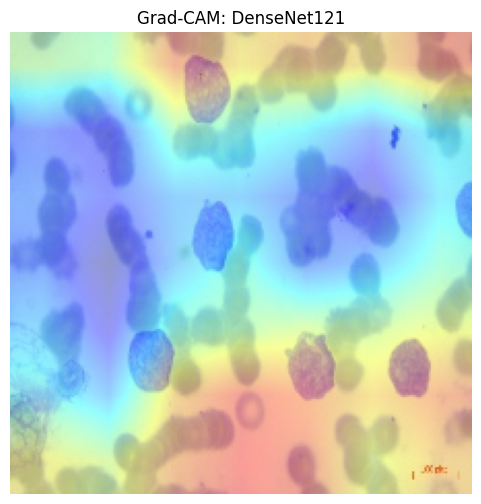

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_1766']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


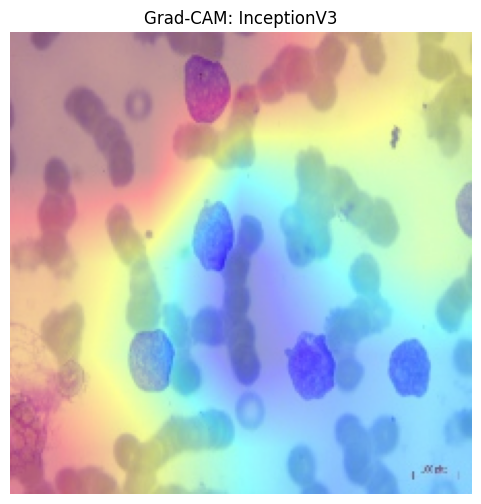

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_2081']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


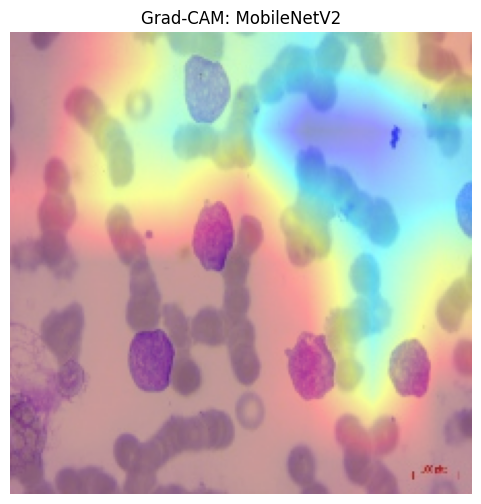

In [ ]:
# Show Grad-CAMs one by one
image_path = "/content/leukemia_dataset/Original/Early/WBC-Malignant-Early-001.jpg"

show_gradcam(models['DenseNet121'], image_path)
show_gradcam(models['InceptionV3'], image_path)
show_gradcam(models['MobileNetV2'], image_path)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


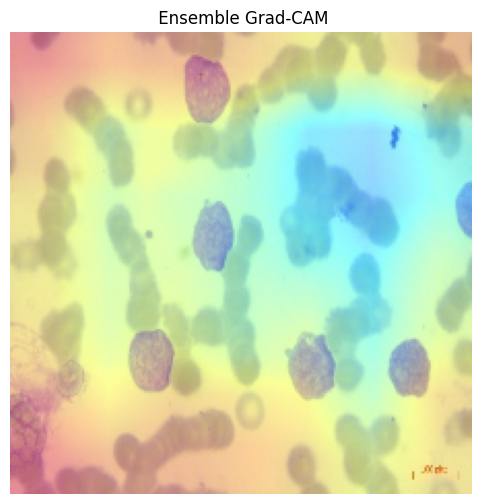

In [ ]:
# Show ensemble Grad-CAM (average heatmap)
show_ensemble_gradcam(models, image_path)


In [ ]:
import json

best_ensemble = {
    "models": ['InceptionV3', 'MobileNetV2'],
    "accuracy": 0.9476
}

with open("savedmodels2/best_ensemble.json", "w") as f:
    json.dump(best_ensemble, f)


In [ ]:

import shutil
import os


# Define target path
drive_path = "/content/drive/MyDrive/leukemia_models"
os.makedirs(drive_path, exist_ok=True)

# Copy the folder
shutil.copytree("savedmodels2", os.path.join(drive_path, "savedmodels2"), dirs_exist_ok=True)

print("Folder 'savedmodels2' has been copied to your Google Drive at:", drive_path)


Folder 'savedmodels2' has been copied to your Google Drive at: /content/drive/MyDrive/leukemia_models


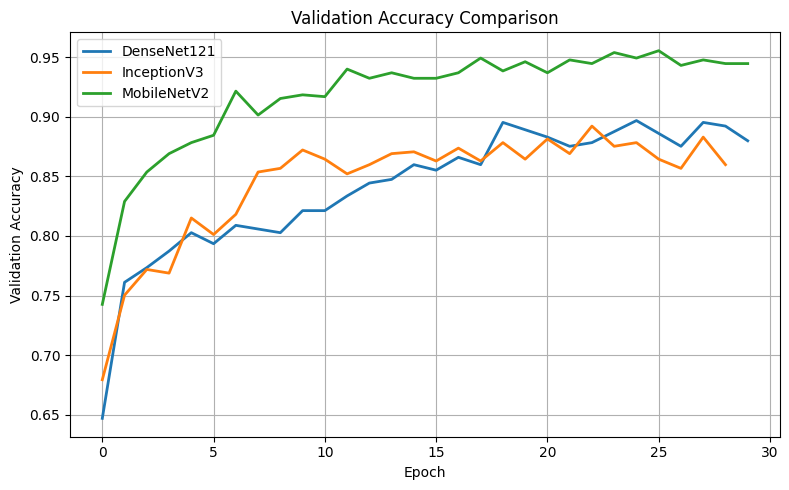

In [ ]:
import matplotlib.pyplot as plt
import pickle

# Load model histories from savedmodels2
with open("savedmodels2/DenseNet121/DenseNet121_history.pkl", "rb") as f:
    densenet_history = pickle.load(f)

with open("savedmodels2/InceptionV3/InceptionV3_history.pkl", "rb") as f:
    inception_history = pickle.load(f)

with open("savedmodels2/MobileNetV2/MobileNetV2_history.pkl", "rb") as f:
    mobilenet_history = pickle.load(f)


# Plot combined validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(densenet_history['val_accuracy'], label='DenseNet121', linewidth=2)
plt.plot(inception_history['val_accuracy'], label='InceptionV3', linewidth=2)
plt.plot(mobilenet_history['val_accuracy'], label='MobileNetV2', linewidth=2)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


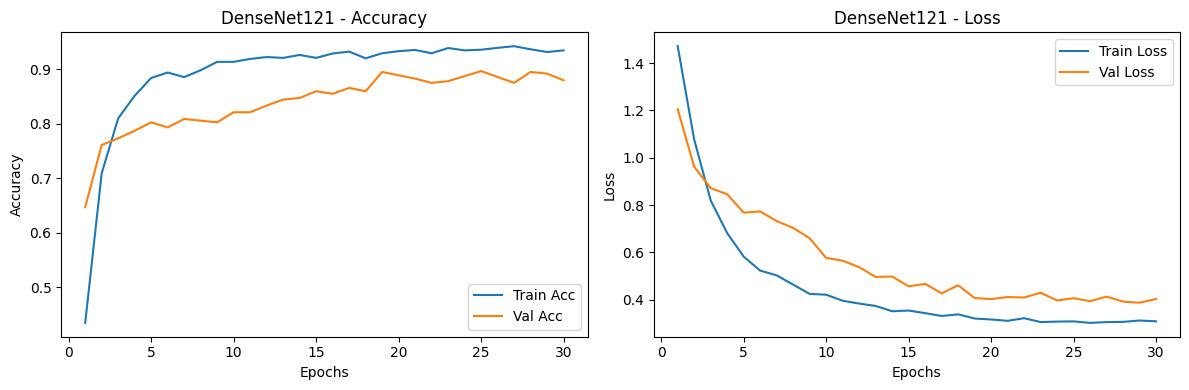

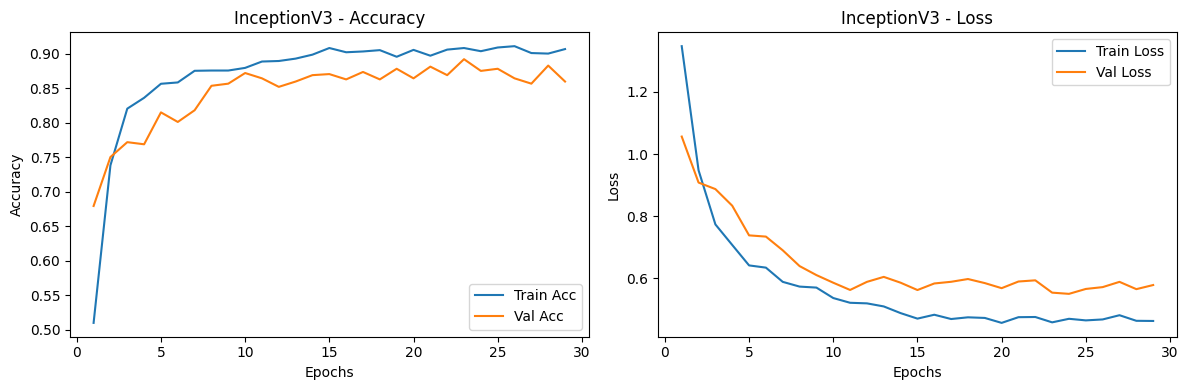

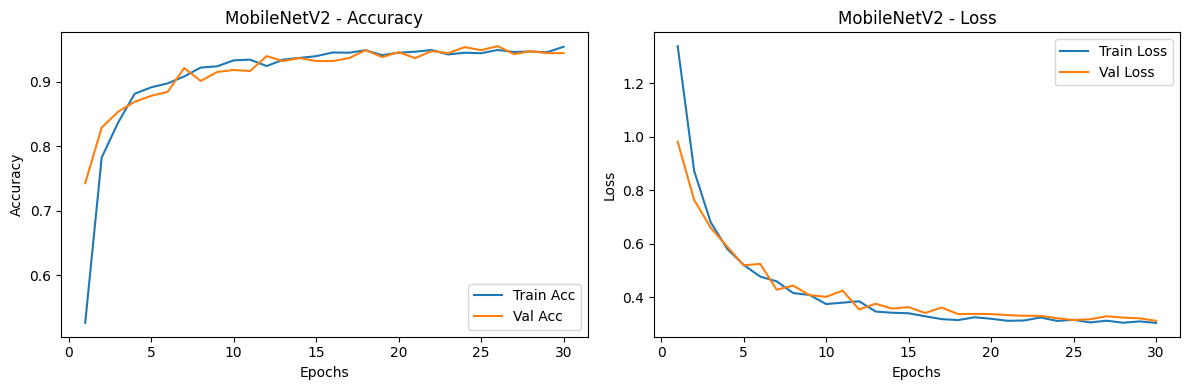

In [ ]:
def plot_history(history, model_name):
    acc = history['accuracy']
    val_acc = history['val_accuracy']
    loss = history['loss']
    val_loss = history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Train Acc')
    plt.plot(epochs, val_acc, label='Val Acc')
    plt.title(f'{model_name} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Run this for each model:
plot_history(densenet_history, "DenseNet121")
plot_history(inception_history, "InceptionV3")
plot_history(mobilenet_history, "MobileNetV2")


<Figure size 600x500 with 0 Axes>

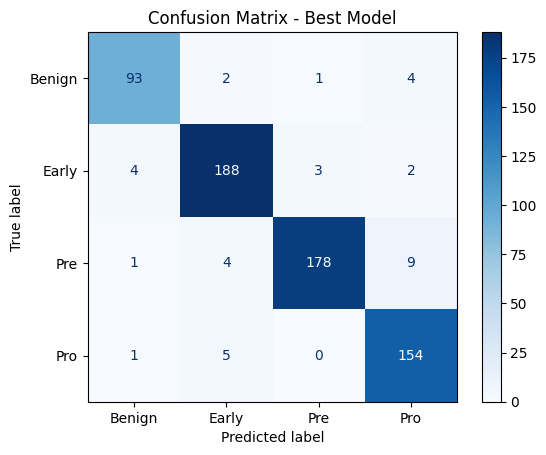

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
labels = ['Benign', 'Early', 'Pre', 'Pro']

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Best Model')
plt.show()


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_6272']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_6702']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_7016']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


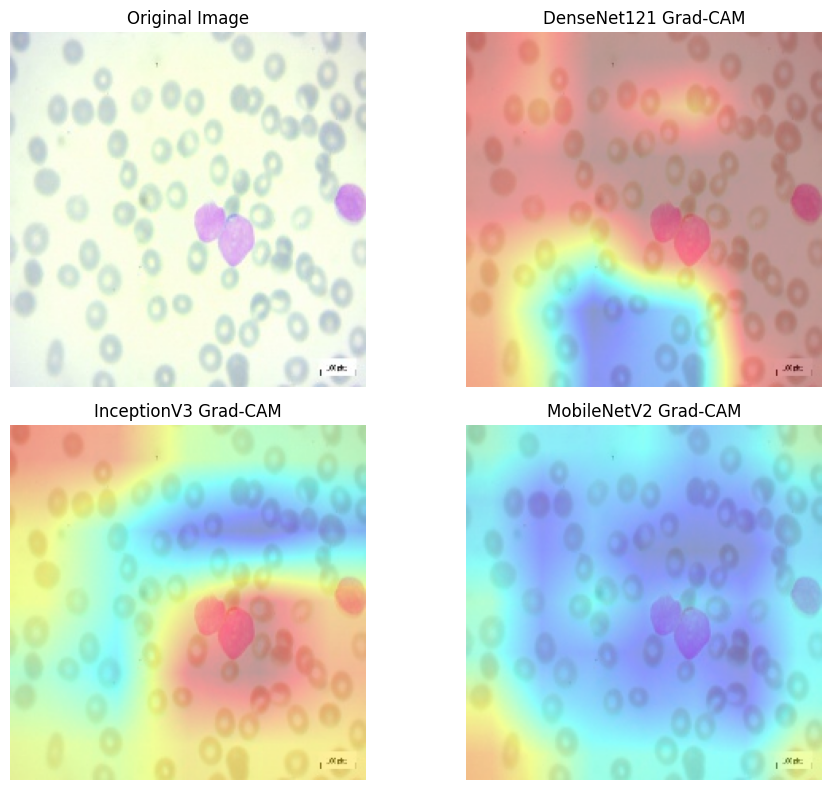

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.applications import DenseNet121, InceptionV3, MobileNetV2

# Load and preprocess image
def load_and_preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    return np.expand_dims(img_array, axis=0), img_array

#  Grad-CAM heatmap function
def get_gradcam_heatmap(model, img_array, class_idx, layer_name):
    grad_model = Model([model.inputs], [model.get_layer(layer_name).output, model.output])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    if grads is None:
        raise ValueError("Gradients could not be computed. Check input or layer name.")

    # Pooled gradients → shape (channels,)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))  # shape (C,)

    # Multiply pooled_grads with each channel of conv_outputs
    conv_outputs = conv_outputs[0]  # shape (H, W, C)
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)  # (H, W)

    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap) + 1e-8  # Avoid divide-by-zero
    return heatmap


# Overlay function
def generate_overlay(image, heatmap):
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(
        cv2.cvtColor((image * 255).astype('uint8'), cv2.COLOR_RGB2BGR),
        0.6, heatmap_color, 0.4, 0
    )
    return overlay

# Model builders (match saved weights)
def build_densenet121():
    base = DenseNet121(weights=None, include_top=False, input_shape=(224, 224, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    output = Dense(4, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=output)
    model.load_weights("savedmodels2/DenseNet121/DenseNet121.weights.h5")
    return model

def build_inceptionv3():
    base = InceptionV3(weights=None, include_top=False, input_shape=(224, 224, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    output = Dense(4, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=output)
    model.load_weights("savedmodels2/InceptionV3/InceptionV3.weights.h5")
    return model

def build_mobilenetv2():
    base = MobileNetV2(weights=None, include_top=False, input_shape=(224, 224, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    output = Dense(4, activation='softmax')(x)
    model = Model(inputs=base.input, outputs=output)
    model.load_weights("savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
    return model

# Full comparison and visualization
def gradcam_comparison(img_path, save=False):
    img_array_exp, img_array = load_and_preprocess_image(img_path)

    models = {
        'DenseNet121': (build_densenet121(), 'conv5_block16_2_conv'),
        'InceptionV3': (build_inceptionv3(), 'mixed10'),
        'MobileNetV2': (build_mobilenetv2(), 'Conv_1')
    }

    overlays = {}

    for name, (model, layer) in models.items():
        preds = model.predict(img_array_exp, verbose=0)
        class_idx = np.argmax(preds[0])
        heatmap = get_gradcam_heatmap(model, img_array_exp, class_idx, layer)
        overlay = generate_overlay(img_array, heatmap)
        overlays[name] = overlay
        if save:
            cv2.imwrite(f"{name}_gradcam.jpg", overlay)

    # Display results
    plt.figure(figsize=(10, 8))
    plt.subplot(2, 2, 1)
    plt.imshow(img_array)
    plt.title("Original Image")
    plt.axis("off")

    for i, (name, overlay) in enumerate(overlays.items(), start=2):
        plt.subplot(2, 2, i)
        plt.imshow(overlay)
        plt.title(f"{name} Grad-CAM")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Usage (change image path)
gradcam_comparison("/content/leukemia_dataset/Original/Pro/WBC-Malignant-Pro-005.jpg", save=True)

In [ ]:
import tensorflow as tf

# --- Load your saved models from Drive ---
DenseNet121_model   = tf.keras.models.load_model('/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121')
MobileNetV2_model  = tf.keras.models.load_model('/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5')
InceptionV3_model  = tf.keras.models.load_model('/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5')

print("DenseNet121, MobileNetV2, and InceptionV3 loaded successfully!")

DenseNet121, MobileNetV2, and InceptionV3 loaded successfully!


In [ ]:
!pip install lime scikit-image -q

import os
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
from tensorflow.keras.models import load_model
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


# Recreate the data generators
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
dataset_dir = "/content/leukemia_dataset/Original" # Assuming this path is correct from previous cells

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    dataset_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


# --- Custom predict function with preprocessing ---
def predict_fn(images, model_name, model):
    images = np.array(images)
    if "DenseNet" in model_name:
        images = tf.keras.applications.densenet.preprocess_input(images)
    elif "Inception" in model_name:
        images = tf.keras.applications.inception_v3.preprocess_input(images)
    elif "MobileNetV2" in model_name:
        images = tf.keras.applications.mobilenet_v2.preprocess_input(images)
    return model.predict(images)

# --- LIME Explainer ---
explainer = lime_image.LimeImageExplainer(random_state=42)

# --- Take a batch of validation images ---
X_batch, y_batch = next(val_generator)   # or test_generator if available
num_samples_to_explain = 2               # how many images to explain

# --- Save results directory ---
save_dir = "/content/drive/MyDrive/leukemia_models/lime_results"
os.makedirs(save_dir, exist_ok=True)

# Define model paths dictionary
model_paths = {
    "DenseNet121": DenseNet121_model,
    "InceptionV3": InceptionV3_model,
    "MobileNetV2": MobileNetV2_model
}


for model_name, model in model_paths.items():
    print(f"\nRunning LIME for {model_name} ...")

    for i in range(num_samples_to_explain):
        img = X_batch[i]
        true_class = np.argmax(y_batch[i])

        # Run LIME
        explanation = explainer.explain_instance(
            img.astype('double'),
            classifier_fn=lambda imgs: predict_fn(imgs, model_name, model),
            top_labels=4,
            hide_color=0,
            num_samples=1000
        )

        predicted_class = np.argmax(model.predict(img[np.newaxis, ...]))

        temp, mask = explanation.get_image_and_mask(
            label=predicted_class,
            positive_only=True,
            num_features=5,
            hide_rest=False
        )

        # Save plot
        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        ax[0].imshow(img)
        ax[0].set_title(f"Original (True: {true_class})")
        ax[0].axis("off")

        ax[1].imshow(mark_boundaries(temp / 255.0, mask))
        ax[1].set_title(f"LIME ({model_name} → Pred: {predicted_class})")
        ax[1].axis("off")

        plt.tight_layout()
        out_path = os.path.join(save_dir, f"{model_name}_sample{i+1}.png")
        plt.savefig(out_path, dpi=150, bbox_inches="tight")
        plt.close(fig)

        print(f" Saved: {out_path}")

Found 2607 images belonging to 4 classes.
Found 649 images belonging to 4 classes.

Running LIME for DenseNet121 ...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 

  0%|          | 0/1000 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 671ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 690ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 543ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 651ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 608ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 618ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 671ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 603ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 647ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
!pip install lime scikit-image -q

import os
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing import image

# --- Image Parameters ---
IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Define functions to rebuild models ---
def build_densenet():
    base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs=base.input, outputs=output, name="DenseNet121")

def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs=base.input, outputs=output, name="InceptionV3")

def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = GlobalAveragePooling2D()(base.output)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs=base.input, outputs=output, name="MobileNetV2")

# --- Map models to their weights files ---
model_paths = {
    "DenseNet121": (build_densenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121/DenseNet121.weights.h5"),
    "InceptionV3": (build_inception, "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"),
    "MobileNetV2": (build_mobilenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
}

# --- Class labels (from your generator) ---
class_labels = {v: k for k, v in val_generator.class_indices.items()}

# --- Load a custom image by path ---
img_path = "/content/leukemia_dataset/Original/Pro/WBC-Malignant-Pro-002.jpg"  #  change here
img = image.load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
img = image.img_to_array(img) / 255.0
true_class_name = os.path.basename(os.path.dirname(img_path))

# --- Prediction function ---
def predict_fn(images, model_name, model):
    images = np.array(images)
    if "DenseNet" in model_name:
        images = tf.keras.applications.densenet.preprocess_input(images)
    elif "Inception" in model_name:
        images = tf.keras.applications.inception_v3.preprocess_input(images)
    elif "MobileNetV2" in model_name:
        images = tf.keras.applications.mobilenet_v2.preprocess_input(images)
    return model.predict(images)

# --- LIME Explainer ---
explainer = lime_image.LimeImageExplainer(random_state=42)

# --- Save results directory ---
save_dir = "/content/drive/MyDrive/leukemia_models/lime_results"
os.makedirs(save_dir, exist_ok=True)

for model_name, (build_fn, weight_path) in model_paths.items():
    print(f"\n Running LIME for {model_name} on {os.path.basename(img_path)} ...")

    # Rebuild architecture and load weights
    model = build_fn()
    model.load_weights(weight_path)

    # Run LIME
    explanation = explainer.explain_instance(
        img.astype('double'),
        classifier_fn=lambda imgs: predict_fn(imgs, model_name, model),
        top_labels=4,
        hide_color=0,
        num_samples=1000
    )

    predicted_class = np.argmax(model.predict(img[np.newaxis, ...]))
    pred_class_name = class_labels[predicted_class]

    _, mask = explanation.get_image_and_mask(
        label=predicted_class,
        positive_only=True,
        num_features=5,
        hide_rest=False
    )

    # --- Save plot with overlay ---
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img)
    ax[0].set_title(f"Original (True: {true_class_name})")
    ax[0].axis("off")

    ax[1].imshow(mark_boundaries(img, mask))  # overlay
    ax[1].set_title(f"LIME ({model_name} → Pred: {pred_class_name})")
    ax[1].axis("off")

    plt.tight_layout()
    out_path = os.path.join(save_dir, f"{model_name}_{os.path.basename(img_path)}.png")
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f" Saved: {out_path}")



 Running LIME for DenseNet121 on WBC-Malignant-Pro-002.jpg ...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 604ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 650ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 600ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 

In [ ]:
import tensorflow as tf
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build functions ---
def build_densenet():
    base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="DenseNet121")

def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="MobileNetV2")

# --- Model weight paths ---
model_paths = {
    "DenseNet121": (build_densenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121/DenseNet121.weights.h5"),
    "InceptionV3": (build_inception, "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"),
    "MobileNetV2": (build_mobilenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
}

# --- Output directories ---
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

# --- Representative dataset for full integer quantisation ---
def representative_data_gen():
    for images, _ in val_generator.take(50):  # adjust batches as per dataset
        yield [images.astype("float32")]

# --- Loop through models ---
for model_name, (build_fn, weight_path) in model_paths.items():
    print(f"\nRebuilding and quantising {model_name} ...")

    # Rebuild architecture and load weights
    model = build_fn()
    model.load_weights(weight_path)

    # Save full model
    h5_path = os.path.join(save_dir, f"{model_name}.h5")
    model.save(h5_path)
    print(f"Saved full model: {h5_path}")

    # Dynamic range quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()

    dyn_path = os.path.join(quant_dir, f"{model_name}_quant.tflite")
    with open(dyn_path, "wb") as f:
        f.write(tflite_model)
    print(f"Saved dynamic quantised model: {dyn_path}")

    # Full integer quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()

    int8_path = os.path.join(quant_dir, f"{model_name}_int8.tflite")
    with open(int8_path, "wb") as f:
        f.write(tflite_model_int8)
    print(f"Saved full int8 quantised model: {int8_path}")



Rebuilding and quantising DenseNet121 ...


Saved full model: /content/drive/MyDrive/leukemia_models/full_models/DenseNet121.h5
Saved artifact at '/tmp/tmp2hes2_oc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_2236')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134463043063248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043061712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043060560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043061328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043065168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043062288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043065360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043060944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463043061520: TensorSpec(shape=(), dtype=tf.resource, name=Non

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


AttributeError: 'DirectoryIterator' object has no attribute 'take'

In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build functions ---
def build_densenet():
    base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="DenseNet121")

def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="MobileNetV2")

# --- Model weight paths ---
model_paths = {
    "DenseNet121": (build_densenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121/DenseNet121.weights.h5"),
    "InceptionV3": (build_inception, "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"),
    "MobileNetV2": (build_mobilenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
}

# --- Output directories ---
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

# --- Representative dataset for full integer quantisation ---
def representative_data_gen():
    for i in range(50):  # number of batches to sample
        images, _ = next(val_generator)   # get a batch from validation generator
        for img in images:
            yield [img[np.newaxis, ...].astype("float32")]

# --- Loop through models ---
for model_name, (build_fn, weight_path) in model_paths.items():
    print(f"\nRebuilding and quantising {model_name} ...")

    # Rebuild architecture and load weights
    model = build_fn()
    model.load_weights(weight_path)

    # Save full model (.h5)
    h5_path = os.path.join(save_dir, f"{model_name}.h5")
    model.save(h5_path)
    print(f"Saved full model: {h5_path}")

    # Dynamic range quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()

    dyn_path = os.path.join(quant_dir, f"{model_name}_quant.tflite")
    with open(dyn_path, "wb") as f:
        f.write(tflite_model)
    print(f"Saved dynamic quantised model: {dyn_path}")

    # Full integer quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()

    int8_path = os.path.join(quant_dir, f"{model_name}_int8.tflite")
    with open(int8_path, "wb") as f:
        f.write(tflite_model_int8)
    print(f"Saved full int8 quantised model: {int8_path}")



Rebuilding and quantising DenseNet121 ...


Saved full model: /content/drive/MyDrive/leukemia_models/full_models/DenseNet121.h5
Saved artifact at '/tmp/tmpn3x2p0r3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_2667')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134463092947472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092947088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092946128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092946512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092946320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092945552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092945360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092945936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463092945744: TensorSpec(shape=(), dtype=tf.resource, name=Non

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build functions ---
def build_densenet():
    base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="DenseNet121")

def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="MobileNetV2")

# --- Model weight paths ---
model_paths = {
    "DenseNet121": (build_densenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121/DenseNet121.weights.h5"),
    "InceptionV3": (build_inception, "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"),
    "MobileNetV2": (build_mobilenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
}

# --- Output directories ---
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

# --- Representative dataset for full integer quantisation ---
def representative_data_gen():
    num_images = 500  # limit calibration to 500 images
    count = 0
    while count < num_images:
        images, _ = next(val_generator)   # get a batch from validation generator
        for img in images:
            if count >= num_images:
                break
            yield [img[np.newaxis, ...].astype("float32")]
            count += 1

# --- Loop through models ---
for model_name, (build_fn, weight_path) in model_paths.items():
    print(f"\nRebuilding and quantising {model_name} ...")

    # Rebuild architecture and load weights
    model = build_fn()
    model.load_weights(weight_path)

    # Save full model (.h5)
    h5_path = os.path.join(save_dir, f"{model_name}.h5")
    model.save(h5_path)

    # Dynamic range quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()

    dyn_path = os.path.join(quant_dir, f"{model_name}_quant.tflite")
    with open(dyn_path, "wb") as f:
        f.write(tflite_model)

    # Full integer quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()

    int8_path = os.path.join(quant_dir, f"{model_name}_int8.tflite")
    with open(int8_path, "wb") as f:
        f.write(tflite_model_int8)

    # --- Report sizes ---
    h5_size = os.path.getsize(h5_path) / (1024*1024)
    dyn_size = os.path.getsize(dyn_path) / (1024*1024)
    int8_size = os.path.getsize(int8_path) / (1024*1024)

    print(f"Model: {model_name}")
    print(f"  Original .h5 size   : {h5_size:.2f} MB")
    print(f"  Quantised .tflite   : {dyn_size:.2f} MB ({h5_size/dyn_size:.2f}x smaller)")
    print(f"  INT8 .tflite        : {int8_size:.2f} MB ({h5_size/int8_size:.2f}x smaller)")



Rebuilding and quantising DenseNet121 ...


Saved artifact at '/tmp/tmp0gnzcoth'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_3098')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134462973399056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973398672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973400592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973398096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973400400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973399824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973399632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973400208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973400016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973399248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462973

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build functions ---
def build_densenet():
    base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="DenseNet121")

def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="MobileNetV2")

# --- Model weight paths ---
model_paths = {
    "DenseNet121": (build_densenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/DenseNet121/DenseNet121.weights.h5"),
    "InceptionV3": (build_inception, "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"),
    "MobileNetV2": (build_mobilenet, "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5")
}

# --- Output directories ---
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

# --- Representative dataset ---
def representative_data_gen():
    num_images = 500
    count = 0
    while count < num_images:
        images, _ = next(val_generator)
        for img in images:
            if count >= num_images:
                break
            yield [img[np.newaxis, ...].astype("float32")]
            count += 1

# --- Helper: Run inference with TFLite model ---
def run_tflite_inference(tflite_path, img):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    input_data = img[np.newaxis, ...].astype(input_details[0]["dtype"])
    interpreter.set_tensor(input_details[0]["index"], input_data)
    interpreter.invoke()
    output_data = interpreter.get_tensor(output_details[0]["index"])
    return np.argmax(output_data)

# --- Loop through models ---
for model_name, (build_fn, weight_path) in model_paths.items():
    print(f"\nRebuilding and quantising {model_name} ...")

    # Rebuild + load weights
    model = build_fn()
    model.load_weights(weight_path)

    # Save full model
    h5_path = os.path.join(save_dir, f"{model_name}.h5")
    model.save(h5_path)

    # Dynamic range quantisation
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    dyn_path = os.path.join(quant_dir, f"{model_name}_quant.tflite")
    with open(dyn_path, "wb") as f:
        f.write(tflite_model)

    # Try Full INT8 quantisation
    int8_path = os.path.join(quant_dir, f"{model_name}_int8.tflite")
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data_gen
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8
        tflite_model_int8 = converter.convert()
        with open(int8_path, "wb") as f:
            f.write(tflite_model_int8)
        print("   Full INT8 quantisation successful.")
    except Exception as e:
        print(f"   Full INT8 failed ({e}), falling back to hybrid quantisation...")
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data_gen
        converter.target_spec.supported_ops = [
            tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
            tf.lite.OpsSet.TFLITE_BUILTINS
        ]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8
        tflite_model_int8 = converter.convert()
        with open(int8_path, "wb") as f:
            f.write(tflite_model_int8)
        print("  Hybrid quantisation saved instead.")

    # --- Report sizes ---
    h5_size = os.path.getsize(h5_path) / (1024*1024)
    dyn_size = os.path.getsize(dyn_path) / (1024*1024)
    int8_size = os.path.getsize(int8_path) / (1024*1024)

    print(f"Model: {model_name}")
    print(f"  Original .h5 size   : {h5_size:.2f} MB")
    print(f"  Quantised .tflite   : {dyn_size:.2f} MB ({h5_size/dyn_size:.2f}x smaller)")
    print(f"  INT8 .tflite        : {int8_size:.2f} MB ({h5_size/int8_size:.2f}x smaller)")

    # --- Inference test ---
    sample_images, _ = next(val_generator)
    test_img = sample_images[0]
    pred_h5 = np.argmax(model.predict(test_img[np.newaxis, ...]))
    pred_dyn = run_tflite_inference(dyn_path, test_img)
    pred_int8 = run_tflite_inference(int8_path, test_img)

    print(f"Predictions on 1 validation image:")
    print(f"  H5 model     : {pred_h5}")
    print(f"  Quantised    : {pred_dyn}")
    print(f"  INT8/Hybrid  : {pred_int8}")



Rebuilding and quantising DenseNet121 ...


Saved artifact at '/tmp/tmp9mtroctm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_3529')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134463063026832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063028944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063027984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063028368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063028176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063030096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063029904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063030480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063030288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063026640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463063

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build MobileNetV2 ---
def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="MobileNetV2")

weight_path = "/content/drive/MyDrive/leukemia_models/savedmodels2/MobileNetV2/MobileNetV2.weights.h5"
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

def representative_data_gen():
    num_images = 500
    count = 0
    while count < num_images:
        images, _ = next(val_generator)
        for img in images:
            if count >= num_images: break
            yield [img[np.newaxis, ...].astype("float32")]
            count += 1

def run_tflite_inference(tflite_path, img):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    input_data = img[np.newaxis, ...].astype(input_details[0]["dtype"])
    interpreter.set_tensor(input_details[0]["index"], input_data)
    interpreter.invoke()
    return np.argmax(interpreter.get_tensor(output_details[0]["index"]))

print("\nQuantising MobileNetV2...")
model = build_mobilenet()
model.load_weights(weight_path)

# Save full .h5
h5_path = os.path.join(save_dir, "MobileNetV2.h5")
model.save(h5_path)

# Dynamic range quantisation
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
dyn_path = os.path.join(quant_dir, "MobileNetV2_quant.tflite")
with open(dyn_path, "wb") as f: f.write(tflite_model)

# Full INT8 quantisation (with fallback)
int8_path = os.path.join(quant_dir, "MobileNetV2_int8.tflite")
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Full INT8 quantisation successful.")
except Exception as e:
    print(f"Full INT8 failed ({e}), using hybrid quantisation...")
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
        tf.lite.OpsSet.TFLITE_BUILTINS
    ]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Hybrid quantisation saved.")

# Sizes
print(f"Original .h5: {os.path.getsize(h5_path)/(1024*1024):.2f} MB")
print(f"Quant .tflite: {os.path.getsize(dyn_path)/(1024*1024):.2f} MB")
print(f"INT8 .tflite : {os.path.getsize(int8_path)/(1024*1024):.2f} MB")

# Inference test
sample_images, _ = next(val_generator)
test_img = sample_images[0]
print("Predictions on 1 val image:")
print(" H5 model  :", np.argmax(model.predict(test_img[np.newaxis, ...])))
print(" Quantised :", run_tflite_inference(dyn_path, test_img))
print(" INT8/Hybrid:", run_tflite_inference(int8_path, test_img))



Quantising MobileNetV2...


Saved artifact at '/tmp/tmpohe4gq21'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_3960')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134463622047760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059814416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059816144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059816528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059816336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059814992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059814224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059814032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059814800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059817872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463059

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build InceptionV3 ---
def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

weight_path = "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

def representative_data_gen():
    num_images = 500
    count = 0
    while count < num_images:
        images, _ = next(val_generator)
        for img in images:
            if count >= num_images: break
            yield [img[np.newaxis, ...].astype("float32")]
            count += 1

def run_tflite_inference(tflite_path, img):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    input_data = img[np.newaxis, ...].astype(input_details[0]["dtype"])
    interpreter.set_tensor(input_details[0]["index"], input_data)
    interpreter.invoke()
    return np.argmax(interpreter.get_tensor(output_details[0]["index"]))

print("\nQuantising InceptionV3...")
model = build_inception()
model.load_weights(weight_path)

# Save full .h5
h5_path = os.path.join(save_dir, "InceptionV3.h5")
model.save(h5_path)

# Dynamic range quantisation
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
dyn_path = os.path.join(quant_dir, "InceptionV3_quant.tflite")
with open(dyn_path, "wb") as f: f.write(tflite_model)

# Full INT8 quantisation (with fallback)
int8_path = os.path.join(quant_dir, "InceptionV3_int8.tflite")
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Full INT8 quantisation successful.")
except Exception as e:
    print(f"Full INT8 failed ({e}), using hybrid quantisation...")
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
        tf.lite.OpsSet.TFLITE_BUILTINS
    ]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Hybrid quantisation saved.")

# Sizes
print(f"Original .h5: {os.path.getsize(h5_path)/(1024*1024):.2f} MB")
print(f"Quant .tflite: {os.path.getsize(dyn_path)/(1024*1024):.2f} MB")
print(f"INT8 .tflite : {os.path.getsize(int8_path)/(1024*1024):.2f} MB")

# Inference test
sample_images, _ = next(val_generator)
test_img = sample_images[0]
print("Predictions on 1 val image:")
print(" H5 model  :", np.argmax(model.predict(test_img[np.newaxis, ...])))
print(" Quantised :", run_tflite_inference(dyn_path, test_img))
print(" INT8/Hybrid:", run_tflite_inference(int8_path, test_img))



Quantising InceptionV3...


Saved artifact at '/tmp/tmpc5m0_bbo'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_4118')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134463622051600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967086352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967084432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967086736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967084240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967085392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967085008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967084624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967085776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967074640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134462967

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Full INT8 quantisation successful.
Original .h5: 85.11 MB
Quant .tflite: 21.32 MB
INT8 .tflite : 21.52 MB
Predictions on 1 val image:
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
 H5 model  : 2


/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


 Quantised : 2
 INT8/Hybrid: 0


In [ ]:
import tensorflow as tf
import numpy as np
import os

IMG_HEIGHT, IMG_WIDTH, NUM_CLASSES = 224, 224, 4

# --- Build InceptionV3 ---
def build_inception():
    base = tf.keras.applications.InceptionV3(weights='imagenet', include_top=False,
                                             input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    output = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inputs=base.input, outputs=output, name="InceptionV3")

weight_path = "/content/drive/MyDrive/leukemia_models/savedmodels2/InceptionV3/InceptionV3.weights.h5"
save_dir = "/content/drive/MyDrive/leukemia_models/full_models"
quant_dir = "/content/drive/MyDrive/leukemia_models/quantised"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(quant_dir, exist_ok=True)

def representative_data_gen():
    num_images = 500
    count = 0
    while count < num_images:
        images, _ = next(val_generator)
        for img in images:
            if count >= num_images: break
            yield [img[np.newaxis, ...].astype("float32")]
            count += 1

def run_tflite_inference(tflite_path, img):
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    input_data = img[np.newaxis, ...].astype(input_details[0]["dtype"])
    interpreter.set_tensor(input_details[0]["index"], input_data)
    interpreter.invoke()
    return np.argmax(interpreter.get_tensor(output_details[0]["index"]))

print("\nQuantising InceptionV3...")
model = build_inception()
model.load_weights(weight_path)

# Save full model in Keras format
keras_path = os.path.join(save_dir, "InceptionV3.keras")
model.save(keras_path)

# Dynamic range quantisation
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
dyn_path = os.path.join(quant_dir, "InceptionV3_quant.tflite")
with open(dyn_path, "wb") as f: f.write(tflite_model)

# Full INT8 quantisation
int8_path = os.path.join(quant_dir, "InceptionV3_int8.tflite")
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Full INT8 quantisation successful.")
except Exception as e:
    print(f"Full INT8 failed ({e}), using hybrid quantisation...")
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
        tf.lite.OpsSet.TFLITE_BUILTINS
    ]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    tflite_model_int8 = converter.convert()
    with open(int8_path, "wb") as f: f.write(tflite_model_int8)
    print("Hybrid quantisation saved.")

# Float16 quantisation
fp16_path = os.path.join(quant_dir, "InceptionV3_fp16.tflite")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model_fp16 = converter.convert()
with open(fp16_path, "wb") as f: f.write(tflite_model_fp16)
print("Float16 quantisation saved.")

# Sizes
print(f"Original .keras: {os.path.getsize(keras_path)/(1024*1024):.2f} MB")
print(f"Quant .tflite  : {os.path.getsize(dyn_path)/(1024*1024):.2f} MB")
print(f"INT8 .tflite   : {os.path.getsize(int8_path)/(1024*1024):.2f} MB")
print(f"FP16 .tflite   : {os.path.getsize(fp16_path)/(1024*1024):.2f} MB")

# Inference test
sample_images, _ = next(val_generator)
test_img = sample_images[0]
print("Predictions on 1 val image:")
print(" H5/Keras model:", np.argmax(model.predict(test_img[np.newaxis, ...])))
print(" Quantised     :", run_tflite_inference(dyn_path, test_img))
print(" INT8/Hybrid   :", run_tflite_inference(int8_path, test_img))
print(" FP16          :", run_tflite_inference(fp16_path, test_img))



Quantising InceptionV3...
Saved artifact at '/tmp/tmp91tgosn4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_4433')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134462973399056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070404240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070404048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402896: TensorSpec(shape=(), dtype=tf.resou

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Full INT8 quantisation successful.
Saved artifact at '/tmp/tmplw0_ywey'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_4433')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134462973399056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070404240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070401552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070404048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134463070402896: TensorSpec(shape=(), dtype=

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


 INT8/Hybrid   : 0
 FP16          : 1


In [ ]:
import tensorflow as tf
import numpy as np
import cv2

# Function to run inference with a TFLite model
def run_tflite_prediction(tflite_path, img_array):
    # Load model
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()

    # Get input/output details
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    # Prepare input
    input_shape = input_details[0]['shape']
    input_dtype = input_details[0]['dtype']

    # Resize image to expected size (224x224 here)
    img_resized = cv2.resize(img_array, (224, 224))
    img_resized = img_resized.astype(input_dtype)

    # Add batch dimension
    input_data = np.expand_dims(img_resized, axis=0)

    # Set input tensor
    interpreter.set_tensor(input_details[0]['index'], input_data)

    # Run inference
    interpreter.invoke()

    # Get output
    predictions = interpreter.get_tensor(output_details[0]['index'])[0]
    return predictions, np.argmax(predictions)

# Example usage
img_path = "/content/leukemia_dataset/Original/Pro/WBC-Malignant-Pro-008.jpg"  #  test image
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Paths to quantised models
dyn_tflite_path = "/content/drive/MyDrive/leukemia_models/quantised/InceptionV3_quant.tflite"
int8_tflite_path = "/content/drive/MyDrive/leukemia_models/quantised/InceptionV3_int8.tflite"
fp16_tflite_path = "/content/drive/MyDrive/leukemia_models/quantised/InceptionV3_fp16.tflite"

print("Dynamic Range Quantised:")
preds, label = run_tflite_prediction(dyn_tflite_path, img)
print(" Label:", label, " Probabilities:", preds)

print("\nINT8 Quantised:")
preds, label = run_tflite_prediction(int8_tflite_path, img)
print(" Label:", label, " Probabilities:", preds)

print("\nFloat16 Quantised:")
preds, label = run_tflite_prediction(fp16_tflite_path, img)
print(" Label:", label, " Probabilities:", preds)


Dynamic Range Quantised:
 Label: 1  Probabilities: [1.712634e-15 1.000000e+00 0.000000e+00 0.000000e+00]

INT8 Quantised:
 Label: 3  Probabilities: [-127 -124 -112  106]

Float16 Quantised:
 Label: 1  Probabilities: [4.1794239e-05 9.9995816e-01 0.0000000e+00 0.0000000e+00]
